# Person 4 — Integration and Evaluation
**AI-Driven Mobility Prediction in 6G** · compares nine handover-preparation approaches on identical held-out trips.

Run from the project folder (the one that contains `train_model.ipynb` and `handover_simulator.ipynb`).
This notebook **only reads** existing work and **only writes** to `integration_results/`.

| # | Approach | Source of the target-cell guess |
|---|---|---|
| 1 | Reactive | none — preparation starts at the handover trigger |
| 2 | Movement-rule | current speed and heading projected 3 s ahead |
| 3 | Pre-trained GRU | `artifacts/pretrained.pt` |
| 4–6 | Scratch GRU (10 / 25 / 50 trips) | `artifacts/scratch_{10,25,50}.pt` |
| 7–9 | Fine-tuned GRU (10 / 25 / 50 trips) | `artifacts/finetuned_{10,25,50}.pt` |

**How the existing work is connected**

* Person 1 / 2 (`train_model.ipynb`): trip generator, `encode`, `make_windows`, `MobilityGRU`, `predict`, `load_model`
  are pulled out of that notebook's own cells with `ast` and executed unchanged.
* Person 3 (`handover_simulator.ipynb`): `run_simulation`, `nearest_cell`, `predict_movement_cell` and all constants
  are pulled out the same way. Every simulation gets a fresh namespace, so state is reset for every strategy.

**Order of operations (no test leakage)**: validation trips → validation predictions from checkpoints → threshold grid sweep →
**freeze thresholds** → only then load the test trips and evaluate all approaches. The whole procedure runs twice
and the two runs are compared.

## 1. Settings

In [1]:
import ast
import copy
import csv
import hashlib
import io
import json
import math
import platform
import random
import subprocess
import sys
from pathlib import Path
from types import MappingProxyType, SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display, Markdown
except ImportError:  # plain-Python fallback
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

    def Markdown(text):
        return text

# ---- paths (inputs are read-only; OUT_DIR is the only place this notebook writes) ----
PROJECT_DIR = Path(".").resolve()
DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
OUT_DIR = PROJECT_DIR / "integration_results"
TRAIN_NB = PROJECT_DIR / "train_model.ipynb"
SIM_NB = PROJECT_DIR / "handover_simulator.ipynb"
assert TRAIN_NB.exists() and SIM_NB.exists(), "Run this notebook from the project folder."

# ---- experiment settings ----
INTEGRATION_SEED = 42                      # seeds Python / NumPy / PyTorch at the start of every run
VAL_SPLIT, TEST_SPLIT = "morning_val", "morning_test"
THRESHOLD_GRID = (0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99)
DEFAULT_THRESHOLD = 0.70                   # only used by strategies that ignore it (reactive, movement-rule)
PREDICTION_TOLERANCE = 1e-4                # checkpoint-vs-CSV consistency check

GRU_MODELS = ["pretrained", "scratch_10", "scratch_25", "scratch_50",
              "finetuned_10", "finetuned_25", "finetuned_50"]
APPROACH_ORDER = ["reactive", "movement_rule"] + GRU_MODELS
SHORT = {"reactive": "Reactive", "movement_rule": "Movement\nrule", "pretrained": "Pre-trained",
         "scratch_10": "Scratch\n10", "scratch_25": "Scratch\n25", "scratch_50": "Scratch\n50",
         "finetuned_10": "Fine-tuned\n10", "finetuned_25": "Fine-tuned\n25", "finetuned_50": "Fine-tuned\n50"}
DISPLAY = {k: v.replace("\n", " ") for k, v in SHORT.items()}
DISPLAY["scratch_10"], DISPLAY["scratch_25"], DISPLAY["scratch_50"] = "Scratch GRU (10 trips)", "Scratch GRU (25 trips)", "Scratch GRU (50 trips)"
DISPLAY["finetuned_10"], DISPLAY["finetuned_25"], DISPLAY["finetuned_50"] = "Fine-tuned GRU (10 trips)", "Fine-tuned GRU (25 trips)", "Fine-tuned GRU (50 trips)"
DISPLAY["pretrained"] = "Pre-trained GRU"
FAMILY = {"reactive": "baseline", "movement_rule": "baseline", "pretrained": "pretrained"}
FAMILY.update({k: k.split("_")[0] for k in GRU_MODELS[1:]})
STRATEGY = {"reactive": "reactive", "movement_rule": "movement"}
STRATEGY.update({k: "model" for k in GRU_MODELS})
ADAPT_TRIPS = {k: (int(k.split("_")[1]) if "_" in k else None) for k in GRU_MODELS}

COLORS = {"reactive": "#7f7f7f", "movement_rule": "#CC79A7", "pretrained": "#0072B2",
          "scratch_10": "#E69F00", "scratch_25": "#E69F00", "scratch_50": "#E69F00",
          "finetuned_10": "#009E73", "finetuned_25": "#009E73", "finetuned_50": "#009E73"}


def inside_out_dir(path):
    path = Path(path).resolve()
    if OUT_DIR.resolve() not in path.parents:
        raise PermissionError(f"Refusing to write outside integration_results/: {path}")
    return path


OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / "validation_predictions").mkdir(exist_ok=True)
print("Project folder :", PROJECT_DIR)
print("Output folder  :", OUT_DIR)

Project folder : X:\Study\Subjects\CN\Mini Project CN
Output folder  : X:\Study\Subjects\CN\Mini Project CN\integration_results


## 2. Load the existing implementations (read-only)
`collect_definitions` parses a notebook's JSON, finds named top-level functions, classes and assignments, and returns their
**original source text**. Nothing in `train_model.ipynb` or `handover_simulator.ipynb` is modified or executed as a whole
(their top-level training, file-writing and display code is never run).

In [2]:
def collect_definitions(nb_path, wanted):
    """Return {name: source} for top-level defs/classes/assignments in a notebook (last definition wins)."""
    nb = json.loads(Path(nb_path).read_text(encoding="utf-8"))
    found = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        source = "".join(cell["source"])
        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue
        lines = source.splitlines()
        for node in tree.body:
            if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
                names = [node.name]
            elif isinstance(node, ast.Assign):
                names = [t.id for t in node.targets if isinstance(t, ast.Name)]
            else:
                continue
            for name in names:
                if name in wanted:
                    start = min([node.lineno] + [d.lineno for d in getattr(node, "decorator_list", [])])
                    found[name] = "\n".join(lines[start - 1:node.end_lineno])
    missing = sorted(set(wanted) - set(found))
    assert not missing, f"{nb_path.name}: could not find {missing}"
    return found


# ---- Person 1 / 2: train_model.ipynb ----
P1_SETTING_NAMES = ["seed", "hidden_size", "pretrain_epochs", "adapt_epochs", "batch_size", "learning_rate", "patience"]
P1_PLAIN = ["PLACES", "BASE_STATIONS", "NOISE_M", "SPLITS", "columns",
            "serving_cell", "pick_stops", "make_trip", "read_trips", "encode", "make_windows"]
P1_TORCH = ["MobilityGRU", "predict", "load_model"]
P1_SRC = collect_definitions(TRAIN_NB, P1_SETTING_NAMES + P1_PLAIN + P1_TORCH)
P1_SETTINGS = {n: ast.literal_eval(P1_SRC[n].split("=", 1)[1].strip()) for n in P1_SETTING_NAMES}

# ---- Person 3: handover_simulator.ipynb ----
P3_NAMES = ["BASE_STATIONS", "CAPACITY_PER_CELL", "CAPACITY", "PREPARATION_DELAY", "RESERVATION_LIFETIME",
            "CONFIDENCE_THRESHOLD", "PROJECTION_SECONDS", "nearest_cell", "predict_movement_cell", "run_simulation"]
P3_SRC = collect_definitions(SIM_NB, P3_NAMES)
P3_CODE = compile("\n\n".join(P3_SRC.values()), str(SIM_NB), "exec")


def p3_namespace():
    ns = {"np": np, "pd": pd, "math": math}
    exec(P3_CODE, ns)
    return ns


P3_CONSTANTS = {k: p3_namespace()[k] for k in ["CAPACITY", "CAPACITY_PER_CELL", "PREPARATION_DELAY",
                                               "RESERVATION_LIFETIME", "CONFIDENCE_THRESHOLD", "PROJECTION_SECONDS"]}
assert P3_CONSTANTS["CAPACITY"] == P3_CONSTANTS["CAPACITY_PER_CELL"], "Person 3's two capacity values disagree"
PREP_DELAY = P3_CONSTANTS["PREPARATION_DELAY"]
LIFETIME = P3_CONSTANTS["RESERVATION_LIFETIME"]
print("Person 1 settings (from train_model.ipynb):", P1_SETTINGS)
print("Person 3 constants (from handover_simulator.ipynb):", P3_CONSTANTS)
print(f"Person 3's default confidence threshold {P3_CONSTANTS['CONFIDENCE_THRESHOLD']} is NOT used for learned models; "
      "thresholds come from validation.")

# ---- PyTorch (optional) ----
try:
    import torch
    from torch import nn
    torch.set_num_threads(2)
    torch.use_deterministic_algorithms(True)   # same settings as train_model.ipynb
    TORCH_OK, TORCH_VERSION = True, torch.__version__
except ImportError:
    torch = nn = None
    TORCH_OK, TORCH_VERSION = False, None

# Person 1's exact code, executed in its own namespace
P1 = {"np": np, "csv": csv, "math": math, "random": random, "Path": Path, "output_dir": ARTIFACT_DIR,
      "torch": torch, "nn": nn}
for name in P1_PLAIN:
    exec(P1_SRC[name], P1)
if TORCH_OK:
    for name in P1_TORCH:
        exec(P1_SRC[name], P1)
print("PyTorch available:", TORCH_OK, TORCH_VERSION or "")

Person 1 settings (from train_model.ipynb): {'seed': 42, 'hidden_size': 32, 'pretrain_epochs': 20, 'adapt_epochs': 40, 'batch_size': 512, 'learning_rate': 0.001, 'patience': 8}
Person 3 constants (from handover_simulator.ipynb): {'CAPACITY': 10, 'CAPACITY_PER_CELL': 10, 'PREPARATION_DELAY': 2.0, 'RESERVATION_LIFETIME': 5.0, 'CONFIDENCE_THRESHOLD': 0.7, 'PROJECTION_SECONDS': 3.0}
Person 3's default confidence threshold 0.7 is NOT used for learned models; thresholds come from validation.


PyTorch available: True 2.15.0+cpu


## 3. Protect previous work: fingerprint every existing file

In [3]:
def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def snapshot_existing_files():
    files = [p for p in [TRAIN_NB, SIM_NB, PROJECT_DIR / "README.md", PROJECT_DIR / "proposed-plan.md",
                         PROJECT_DIR / "requirements.txt", PROJECT_DIR / ".gitignore"] if p.exists()]
    for folder in (DATA_DIR, ARTIFACT_DIR):
        if folder.exists():
            files += sorted(p for p in folder.rglob("*") if p.is_file())
    return {str(p.relative_to(PROJECT_DIR)): sha256_file(p) for p in files}


FILES_BEFORE = snapshot_existing_files()
print(f"{len(FILES_BEFORE)} existing files fingerprinted (notebooks, docs, data/, artifacts/).")
print("data/ exists     :", DATA_DIR.exists(), "| artifacts/ exists:", ARTIFACT_DIR.exists())

26 existing files fingerprinted (notebooks, docs, data/, artifacts/).
data/ exists     : True | artifacts/ exists: True


## 4. Data, prediction and simulator helpers
* `load_split` reads `data/<split>.csv`. **If the file is missing**, the trips are rebuilt *in memory only* with Person 1's own generator
  and Person 1's fixed seed (`SPLITS`), written through the same `csv.writer` into a buffer, and **never saved to `data/`**.
  The source (`file` or `RECONSTRUCTED`) and a SHA-256 of the CSV bytes are recorded so they can be compared with the real file.
* `validate_prediction_frame` rejects any prediction file that does not line up exactly with the trips it will be replayed on.
* `simulate` runs **Person 3's unmodified `run_simulation`** in a fresh namespace on a fresh copy of the trips.

In [4]:
def trips_from_frame(df):
    """Same checks and dtype as Person 1's read_trips, but from a DataFrame."""
    assert list(df.columns) == P1["columns"], "Unexpected CSV columns"
    trips = {}
    for trip_id, group in df.groupby("trip_id", sort=True):
        readings = group.iloc[:, 1:].to_numpy(dtype=np.float64).astype(np.float32)
        assert readings.shape[1] == 6 and len(readings) >= 8 and np.isfinite(readings).all()
        assert np.array_equal(readings[:, 0], np.arange(len(readings)))
        assert np.isin(readings[:, 5], [0, 1, 2, 3]).all()
        trips[int(trip_id)] = readings
    return trips


def load_split(name):
    spec = {s[0]: s for s in P1["SPLITS"]}[name]
    _, scenario, trip_count, split_seed = spec
    path = DATA_DIR / f"{name}.csv"
    if path.exists():
        raw, source = path.read_bytes(), "file"
    else:
        buffer = io.StringIO(newline="")
        writer = csv.writer(buffer)
        writer.writerow(P1["columns"])
        rng = random.Random(split_seed)
        for trip_id in range(trip_count):
            writer.writerows(P1["make_trip"](trip_id, scenario, rng))
        raw = buffer.getvalue().encode()
        source = "RECONSTRUCTED in memory from Person 1's generator + seed (data file missing; nothing written to data/)"
    df = pd.read_csv(io.BytesIO(raw))
    trips = trips_from_frame(df)
    assert sorted(trips) == list(range(trip_count))
    if source == "file":   # exact parity with Person 1's own reader
        reference = P1["read_trips"](path)
        assert all(np.array_equal(reference[k], trips[k]) for k in reference)
    return {"name": name, "source": source, "sha256": sha256_bytes(raw), "df": df, "trips": trips,
            "n_trips": trip_count, "scenario": scenario, "seed": split_seed}


def expected_prediction_keys(trips):
    # Person 1's make_windows covers reading_index 4 .. len-4 of every trip
    return {(tid, float(t)) for tid, arr in trips.items() for t in range(4, len(arr) - 3)}


def validate_prediction_frame(df, trips, label):
    prob_cols = [f"p_cell_{c}" for c in range(4)]
    need = ["trip_id", "time_s", "serving_cell", "target_time_s"] + prob_cols
    if list(df.columns) != need:
        raise ValueError(f"{label}: unexpected columns {list(df.columns)}")
    if not np.equal(df.trip_id, np.floor(df.trip_id)).all():
        raise ValueError(f"{label}: trip IDs must be integers")
    if not np.equal(df.serving_cell, np.floor(df.serving_cell)).all():
        raise ValueError(f"{label}: serving cells must be integers")
    if not np.allclose(df.target_time_s, df.time_s + 3, rtol=0, atol=1e-6):
        raise ValueError(f"{label}: target_time_s must be time_s + 3")
    keys = [(int(a), float(b)) for a, b in zip(df.trip_id, df.time_s)]
    if len(keys) != len(set(keys)) or set(keys) != expected_prediction_keys(trips):
        raise ValueError(f"{label}: (trip_id, time_s) rows do not match the replayed trips")
    probs = df[prob_cols].to_numpy(dtype=float)
    if not np.isfinite(probs).all() or (probs < 0).any() or not np.allclose(probs.sum(axis=1), 1, atol=1e-5):
        raise ValueError(f"{label}: probabilities are not valid distributions")
    cells = {(tid, float(t)): int(arr[t, 5]) for tid, arr in trips.items() for t in range(len(arr))}
    if any(cells[k] != int(c) for k, c in zip(keys, df.serving_cell)):
        raise ValueError(f"{label}: serving_cell column disagrees with the trips")
    return True


def build_lookup(pred_df):
    # identical to Person 3's pred_lookup construction
    return {(int(r.trip_id), float(r.time_s)): r for r in pred_df.itertuples(index=False)}


def predict_with_checkpoint(model_name, trips):
    """Saved checkpoint + Person 1's load_model / make_windows / predict -> prediction frame in the *_predictions.csv layout."""
    model = P1["load_model"](model_name)
    inputs, labels, details = P1["make_windows"](trips)
    probabilities = P1["predict"](model, inputs)
    assert probabilities.shape == (len(labels), 4) and np.isfinite(probabilities).all()
    assert {(int(a), float(b)) for a, b, _ in details} == expected_prediction_keys(trips)
    rows = []
    for index, (trip_id, time, current_cell) in enumerate(details):
        rows.append([int(trip_id), float(time), int(current_cell), float(time + 3)] + probabilities[index].tolist())
    frame = pd.DataFrame(rows, columns=["trip_id", "time_s", "serving_cell", "target_time_s",
                                        "p_cell_0", "p_cell_1", "p_cell_2", "p_cell_3"])
    n_params = int(sum(p.numel() for p in model.parameters()))
    return frame, {"hidden_size": int(model.gru.hidden_size), "n_parameters": n_params}


def simulate(strategy, trips_df, pred_lookup, threshold):
    """Person 3's run_simulation, fresh namespace + fresh trip copy => independent state per call."""
    ns = p3_namespace()
    ns["CONFIDENCE_THRESHOLD"] = float(threshold)
    ns["trips_df"] = trips_df.copy()
    ns["pred_lookup"] = pred_lookup
    return ns["run_simulation"](strategy)


def metrics_row(result):
    handovers = int(result["handovers"])
    correct, wrong = int(result["correct_reservations"]), int(result["wrong_reservations"])
    return {"mean_delay_s": float(result["mean_delay"]),
            "p95_delay_s": float(result["p95_delay"]),
            "correct_early_rate_pct": float(result["correct_early_preparation_rate"]) * 100.0,
            "unused_capacity_s": float(result["unused_capacity_seconds"]),
            "handovers": handovers, "correct_reservations": correct, "wrong_reservations": wrong,
            "expired_reservations": int(result["expired_reservations"]),
            "no_reservation_handovers": handovers - correct - wrong}


def select_threshold(rows):
    """Max correct early rate; ties -> lower unused capacity; ties -> higher threshold."""
    return min(rows, key=lambda r: (-round(r["correct_early_rate_pct"], 9),
                                    round(r["unused_capacity_s"], 9), -r["threshold"]))


def count_handovers_independently(df):
    ordered = df.sort_values(["trip_id", "time_s"])
    changed = ordered.groupby("trip_id")["serving_cell"].diff().fillna(0) != 0
    return int(changed.sum())


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_OK:
        torch.manual_seed(seed)

## 5. Self-tests (run before any result is produced)
1. Hand-built scenarios with known answers go through Person 3's real `run_simulation`.
2. An independently written reference simulator is compared with it on validation trips (baselines, and random probabilities
   used **only** as a code check — they are never reported).
3. The tie-break rule for threshold selection is checked.
Test trips are not touched here.

In [5]:
# ---------- 1. known-answer scenarios ----------
def scenario_df(n_users=1, handover_at=10, length=14):
    rows = []
    for uid in range(n_users):
        for t in range(length):
            cell = 0 if handover_at is None or t < handover_at else 1
            rows.append([uid, float(t), 100.0, 100.0, 0.0, 0.0, cell])
    return pd.DataFrame(rows, columns=P1["columns"])


def fake_lookup(entries):
    out = {}
    for (uid, t), (target, conf) in entries.items():
        probs = [(1 - conf) / 3] * 4
        probs[target] = conf
        out[(uid, float(t))] = SimpleNamespace(**{f"p_cell_{c}": probs[c] for c in range(4)})
    return out


def expect(result, **want):
    for key, value in want.items():
        assert math.isclose(result[key], value, abs_tol=1e-9), (key, result[key], value)


# T1 prediction 3 s early (t=7, ready t=9) -> no remaining delay
r = simulate("model", scenario_df(), fake_lookup({(0, 7): (1, 0.9)}), 0.7)
expect(r, handovers=1, mean_delay=0.0, p95_delay=0.0, correct_reservations=1, wrong_reservations=0,
       expired_reservations=0, unused_capacity_seconds=0.0, correct_early_preparation_rate=1.0)
# T2 prediction only 1 s early (ready t=11, handover t=10) -> 1 s remaining
r = simulate("model", scenario_df(), fake_lookup({(0, 9): (1, 0.9)}), 0.7)
expect(r, mean_delay=1.0, correct_reservations=1, unused_capacity_seconds=0.0)
# T3 wrong target: full reactive delay, reservation expires unused (5 capacity-seconds)
r = simulate("model", scenario_df(), fake_lookup({(0, 7): (2, 0.9)}), 0.7)
expect(r, mean_delay=PREP_DELAY, correct_reservations=0, wrong_reservations=1, expired_reservations=1,
       unused_capacity_seconds=LIFETIME, correct_early_preparation_rate=0.0)
# T4 threshold: 0.6 < 0.7 -> no reservation; 0.6 >= 0.6 -> reservation
r = simulate("model", scenario_df(), fake_lookup({(0, 7): (1, 0.6)}), 0.7)
expect(r, mean_delay=PREP_DELAY, correct_reservations=0, wrong_reservations=0, unused_capacity_seconds=0.0)
r = simulate("model", scenario_df(), fake_lookup({(0, 7): (1, 0.6)}), 0.6)
expect(r, mean_delay=0.0, correct_reservations=1)
# T5 capacity: 11 users want cell 1 at once, capacity 10 -> the 11th gets nothing
r = simulate("model", scenario_df(11), fake_lookup({(u, 7): (1, 0.9) for u in range(11)}), 0.7)
expect(r, handovers=11, correct_reservations=10, mean_delay=PREP_DELAY / 11)
# T6 reservation that expires inside the run, no handover
r = simulate("model", scenario_df(handover_at=None), fake_lookup({(0, 3): (1, 0.9)}), 0.7)
expect(r, handovers=0, expired_reservations=1, unused_capacity_seconds=LIFETIME, mean_delay=0.0)
# T7 reservation still pending when the run ends is also unused capacity
r = simulate("model", scenario_df(handover_at=None), fake_lookup({(0, 12): (1, 0.9)}), 0.7)
expect(r, expired_reservations=0, unused_capacity_seconds=LIFETIME)
# T8 reactive never reserves
r = simulate("reactive", scenario_df(5), {}, 0.7)
expect(r, handovers=5, mean_delay=PREP_DELAY, p95_delay=PREP_DELAY, correct_reservations=0, unused_capacity_seconds=0.0)
print("1. known-answer scenarios through Person 3's run_simulation: 8/8 passed")


# ---------- 2. independent reference simulator ----------
def reference_simulation(df, strategy, probs, threshold):
    """Written separately from Person 3's code, from the plan's rules."""
    cap, prep, life, horizon = (P3_CONSTANTS[k] for k in ["CAPACITY", "PREPARATION_DELAY",
                                                          "RESERVATION_LIFETIME", "PROJECTION_SECONDS"])
    stations = [(100, 100), (300, 100), (100, 300), (300, 300)]
    records = sorted(df.itertuples(index=False), key=lambda r: (r.time_s, r.trip_id))
    held, last_cell, delays = [], {}, []
    ok = bad = expired = 0
    unused = 0.0
    for r in records:
        uid, now, cell = int(r.trip_id), float(r.time_s), int(r.serving_cell)
        alive = []
        for h in held:
            if now >= h["expiry"]:
                unused += h["expiry"] - h["created"]
                expired += 1
            else:
                alive.append(h)
        held = alive
        if uid in last_cell and last_cell[uid] != cell:
            mine = [h for h in held if h["uid"] == uid]
            if mine and mine[0]["cell"] == cell:
                delays.append(max(0.0, mine[0]["ready"] - now))
                ok += 1
                held.remove(mine[0])
            else:
                bad += 1 if mine else 0
                delays.append(prep)
        last_cell[uid] = cell
        if strategy == "reactive" or any(h["uid"] == uid for h in held):
            continue
        if strategy == "movement":
            fx = r.x_m + r.speed_m_s * horizon * math.cos(r.heading_rad)
            fy = r.y_m + r.speed_m_s * horizon * math.sin(r.heading_rad)
            target = int(np.argmin([(fx - sx) ** 2 + (fy - sy) ** 2 for sx, sy in stations]))
            conf = 1.0
        else:
            p = probs.get((uid, now))
            if p is None:
                continue
            target, conf = int(np.argmax(p)), float(max(p))
        if target == cell or conf < threshold or sum(h["cell"] == target for h in held) >= cap:
            continue
        held.append({"uid": uid, "cell": target, "created": now, "ready": now + prep, "expiry": now + life})
    unused += sum(h["expiry"] - h["created"] for h in held)
    return {"handovers": len(delays), "correct_reservations": ok, "wrong_reservations": bad,
            "expired_reservations": expired, "unused_capacity_seconds": unused,
            "mean_delay": float(np.mean(delays)), "p95_delay": float(np.percentile(delays, 95))}


def same(a, b):
    for k in ["handovers", "correct_reservations", "wrong_reservations", "expired_reservations"]:
        assert a[k] == b[k], (k, a[k], b[k])
    for k in ["unused_capacity_seconds", "mean_delay", "p95_delay"]:
        assert math.isclose(a[k], b[k], abs_tol=1e-9), (k, a[k], b[k])


_val = load_split(VAL_SPLIT)
for strategy in ("reactive", "movement"):
    same(simulate(strategy, _val["df"], {}, 0.7), reference_simulation(_val["df"], strategy, {}, 0.7))
_rng = np.random.default_rng(12345)    # CODE CHECK ONLY: random probabilities, never reported
_probs = {k: _rng.dirichlet([0.5] * 4) for k in sorted(expected_prediction_keys(_val["trips"]))}
_lookup = {k: SimpleNamespace(**{f"p_cell_{c}": float(p[c]) for c in range(4)}) for k, p in _probs.items()}
for th in (0.4, 0.7, 0.9):
    same(simulate("model", _val["df"], _lookup, th), reference_simulation(_val["df"], "model", _probs, th))
print("2. Person 3 simulator == independent reference on validation trips (reactive, movement, model x3 thresholds): passed")

# ---------- 3. threshold tie-breaks ----------
rows = [dict(threshold=0.5, correct_early_rate_pct=80.0, unused_capacity_s=10.0),
        dict(threshold=0.6, correct_early_rate_pct=90.0, unused_capacity_s=20.0),
        dict(threshold=0.7, correct_early_rate_pct=90.0, unused_capacity_s=15.0),
        dict(threshold=0.8, correct_early_rate_pct=90.0, unused_capacity_s=15.0)]
assert select_threshold(rows)["threshold"] == 0.8                      # rate tie -> lower unused tie -> higher threshold
assert select_threshold(rows[:2])["threshold"] == 0.6                  # rate beats unused capacity
assert select_threshold(rows[::-1])["threshold"] == 0.8                # independent of grid order
print("3. threshold selection and tie-breaks: passed")
del _val, _rng, _probs, _lookup

1. known-answer scenarios through Person 3's run_simulation: 8/8 passed


2. Person 3 simulator == independent reference on validation trips (reactive, movement, model x3 thresholds): passed
3. threshold selection and tie-breaks: passed


## 6. The complete evaluation pipeline
`run_full_pipeline` performs everything from scratch (re-reads files, reloads checkpoints, rebuilds simulator state):

1. load **validation** trips, generate validation predictions from every available checkpoint;
2. sweep the fixed threshold grid on validation trips and select each learned model's threshold;
3. **freeze** the thresholds (hash recorded; re-checked after testing);
4. only then load the **test** trips and replay all nine approaches with identical trips, start times (all trips start at t = 0 on Person 3's shared clock),
   capacities, preparation delay and reservation lifetime.

A learned model is marked **PENDING** (never estimated or filled in) if its checkpoint or prediction CSV is missing or PyTorch is unavailable.

In [6]:
def run_full_pipeline(label):
    seed_everything(INTEGRATION_SEED)
    info = {"label": label}

    # ---------------- validation phase ----------------
    val = load_split(VAL_SPLIT)
    info["validation_data"] = {k: val[k] for k in ("name", "source", "sha256", "n_trips", "seed")}
    assert (val["df"].groupby("trip_id").time_s.min() == 0).all()
    pending, val_preds, model_info = {}, {}, {}
    for name in GRU_MODELS:
        ckpt = ARTIFACT_DIR / f"{name}.pt"
        if not ckpt.exists():
            pending[name] = f"checkpoint missing: artifacts/{name}.pt"
        elif not TORCH_OK:
            pending[name] = "PyTorch is not installed, so the checkpoint cannot be loaded to make validation predictions"
        else:
            frame, model_info[name] = predict_with_checkpoint(name, val["trips"])
            validate_prediction_frame(frame, val["trips"], f"validation predictions {name}")
            val_preds[name] = frame
    info["val_prediction_sha256"] = {}
    for name, frame in val_preds.items():
        text = frame.to_csv(index=False)
        path = inside_out_dir(OUT_DIR / "validation_predictions" / f"{name}_validation_predictions.csv")
        path.write_text(text, encoding="utf-8", newline="")
        info["val_prediction_sha256"][name] = sha256_bytes(text.encode())

    val_rows, frozen = [], {}
    for key in ("reactive", "movement_rule"):
        r = metrics_row(simulate(STRATEGY[key], val["df"], {}, DEFAULT_THRESHOLD))
        val_rows.append({"approach": key, "threshold": np.nan, "selected": True, "status": "evaluated (no threshold)",
                         "detail": "", **r})
    for name in GRU_MODELS:
        if name in pending:
            val_rows.append({"approach": name, "threshold": np.nan, "selected": False, "status": "PENDING",
                             "detail": pending[name]})
            continue
        lookup = build_lookup(val_preds[name])
        grid = []
        for threshold in THRESHOLD_GRID:
            row = metrics_row(simulate("model", val["df"], lookup, threshold))
            row["threshold"] = float(threshold)
            grid.append(row)
        chosen = select_threshold(grid)
        frozen[name] = chosen["threshold"]
        for row in grid:
            val_rows.append({"approach": name, "selected": row is chosen, "status": "evaluated", "detail": "", **row})
    val_table = pd.DataFrame(val_rows)

    # ---------------- freeze, then touch the test set ----------------
    FROZEN = MappingProxyType(dict(frozen))
    frozen_hash = sha256_bytes(json.dumps(dict(FROZEN), sort_keys=True).encode())
    info["frozen_thresholds"] = dict(FROZEN)
    info["frozen_thresholds_sha256"] = frozen_hash

    test = load_split(TEST_SPLIT)
    info["test_data"] = {k: test[k] for k in ("name", "source", "sha256", "n_trips", "seed")}
    assert (test["df"].groupby("trip_id").time_s.min() == 0).all(), "all trips must share the same start time"
    val_set = {a.tobytes() for a in val["trips"].values()}
    assert not any(a.tobytes() in val_set for a in test["trips"].values()), "validation and test trips overlap"
    test_hash_before = sha256_bytes(test["df"].to_numpy(dtype=float).tobytes())
    expected_handovers = count_handovers_independently(test["df"])

    test_rows, consistency = [], {}
    for key in APPROACH_ORDER:
        base = {"approach": key, "display_name": DISPLAY[key], "family": FAMILY[key],
                "adaptation_trips": ADAPT_TRIPS.get(key), "test_trips": test["n_trips"]}
        if STRATEGY[key] != "model":
            r = metrics_row(simulate(STRATEGY[key], test["df"], {}, DEFAULT_THRESHOLD))
            test_rows.append({**base, "status": "evaluated", "status_detail": "", "confidence_threshold": np.nan, **r})
            continue
        csv_path = ARTIFACT_DIR / f"{key}_predictions.csv"
        if key in pending:
            reason = f"thresholds cannot be frozen: {pending[key]}"
        elif not csv_path.exists():
            reason = f"prediction file missing: artifacts/{key}_predictions.csv"
        else:
            reason = None
        if reason:
            test_rows.append({**base, "status": "PENDING", "status_detail": reason, "confidence_threshold": np.nan})
            continue
        pred_df = pd.read_csv(csv_path)
        validate_prediction_frame(pred_df, test["trips"], f"{key}_predictions.csv")
        r = metrics_row(simulate("model", test["df"], build_lookup(pred_df), FROZEN[key]))
        test_rows.append({**base, "status": "evaluated", "status_detail": "", "confidence_threshold": FROZEN[key], **r})
        # Reject stale predictions that disagree with their saved checkpoint.
        regenerated, _ = predict_with_checkpoint(key, test["trips"])
        cols = [f"p_cell_{c}" for c in range(4)]
        a = regenerated.sort_values(["trip_id", "time_s"])[cols].to_numpy()
        b = pred_df.sort_values(["trip_id", "time_s"])[cols].to_numpy()
        consistency[key] = float(np.abs(a - b).max())
        if consistency[key] > PREDICTION_TOLERANCE:
            raise ValueError(f"{key}: prediction CSV disagrees with its checkpoint "
                             f"(maximum difference {consistency[key]:.6g})")
    test_table = pd.DataFrame(test_rows)

    # ---------------- fairness / integrity checks ----------------
    assert sha256_bytes(test["df"].to_numpy(dtype=float).tobytes()) == test_hash_before, "test trips were modified"
    assert sha256_bytes(json.dumps(dict(FROZEN), sort_keys=True).encode()) == frozen_hash, "thresholds changed after freeze"
    done = test_table[test_table.status == "evaluated"]
    assert done.handovers.eq(expected_handovers).all(), "every approach must see the same handovers"
    assert (done.no_reservation_handovers >= 0).all()
    assert (done.unused_capacity_s % LIFETIME == 0).all() and (done.unused_capacity_s >= LIFETIME * done.expired_reservations).all()
    info["handovers_independent_count"] = expected_handovers
    info["checkpoint_vs_csv_max_abs_diff"] = consistency
    info["pending"] = pending
    info["model_info"] = model_info
    info["test_trips_sha256"] = test_hash_before
    return {"val_table": val_table, "test_table": test_table, "info": info}

## 7. Run 1 and Run 2 (identical settings, from scratch)

In [7]:
RUN1 = run_full_pipeline("run_1")
print("Run 1 done.  validation data:", RUN1["info"]["validation_data"]["source"])
print("             test data      :", RUN1["info"]["test_data"]["source"])
print("Frozen thresholds:", RUN1["info"]["frozen_thresholds"] or "none (no GRU could be evaluated)")
for name, reason in RUN1["info"]["pending"].items():
    print(f"PENDING  {name:13s} -> {reason}")

Run 1 done.  validation data: file
             test data      : file
Frozen thresholds: {'pretrained': 0.6, 'scratch_10': 0.99, 'scratch_25': 0.99, 'scratch_50': 0.5, 'finetuned_10': 0.55, 'finetuned_25': 0.55, 'finetuned_50': 0.5}


In [8]:
RUN2 = run_full_pipeline("run_2")


def table_hash(df):
    return sha256_bytes(df.to_csv(index=False).encode())


repro = {
    "test_comparison_identical": bool(RUN1["test_table"].equals(RUN2["test_table"])),
    "validation_thresholds_identical": bool(RUN1["val_table"].equals(RUN2["val_table"])),
    "frozen_thresholds_identical": RUN1["info"]["frozen_thresholds"] == RUN2["info"]["frozen_thresholds"],
    "validation_prediction_files_identical": RUN1["info"]["val_prediction_sha256"] == RUN2["info"]["val_prediction_sha256"],
    "test_comparison_sha256": [table_hash(RUN1["test_table"]), table_hash(RUN2["test_table"])],
    "validation_thresholds_sha256": [table_hash(RUN1["val_table"]), table_hash(RUN2["val_table"])],
}
numeric = RUN1["test_table"].select_dtypes("number").columns
repro["max_abs_difference_test_metrics"] = float(
    np.nan_to_num((RUN1["test_table"][numeric].astype(float) - RUN2["test_table"][numeric].astype(float)).abs().to_numpy()).max())
repro["all_match"] = all(v for k, v in repro.items() if k.endswith("_identical"))
assert repro["all_match"], "The two runs differ!"
print("Run 2 done. The two complete runs match exactly:", repro["all_match"])
print("Max absolute difference in any test metric:", repro["max_abs_difference_test_metrics"])
RESULT = RUN2        # tables used below (identical to RUN1)

Run 2 done. The two complete runs match exactly: True
Max absolute difference in any test metric: 0.0


## 8. Save tables and settings

In [9]:
def clean(obj):
    if isinstance(obj, dict):
        return {str(k): clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [clean(v) for v in obj]
    if isinstance(obj, (np.floating, float)):
        return None if not math.isfinite(obj) else float(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def write_json(obj, name):
    inside_out_dir(OUT_DIR / name).write_text(json.dumps(clean(obj), indent=2), encoding="utf-8")


COUNT_COLS = ["adaptation_trips", "handovers", "correct_reservations", "wrong_reservations", "expired_reservations",
              "no_reservation_handovers", "test_trips", "total_handovers"]


def write_table(df, name):
    df = df.copy()
    for col in COUNT_COLS:
        if col in df.columns:
            df[col] = df[col].astype("Int64")      # whole numbers stay whole even when PENDING rows are blank
    inside_out_dir(OUT_DIR / name).write_text(df.to_csv(index=False), encoding="utf-8", newline="")


info = RESULT["info"]
val_table, test_table = RESULT["val_table"], RESULT["test_table"]

# ---- validation_thresholds.csv ----
val_cols = ["approach", "status", "detail", "threshold", "selected", "mean_delay_s", "p95_delay_s",
            "correct_early_rate_pct", "unused_capacity_s", "handovers", "correct_reservations",
            "wrong_reservations", "expired_reservations", "no_reservation_handovers"]
write_table(val_table[val_cols], "validation_thresholds.csv")

# ---- test_comparison.csv ----
test_cols = ["approach", "display_name", "family", "adaptation_trips", "status", "status_detail", "confidence_threshold",
             "mean_delay_s", "p95_delay_s", "correct_early_rate_pct", "unused_capacity_s", "handovers",
             "correct_reservations", "wrong_reservations", "expired_reservations", "no_reservation_handovers", "test_trips"]
out_test = test_table[test_cols].rename(columns={
    "mean_delay_s": "mean_handover_delay_s", "p95_delay_s": "p95_handover_delay_s",
    "correct_early_rate_pct": "correct_early_preparation_rate_pct",
    "unused_capacity_s": "unused_reservation_capacity_capacity_s", "handovers": "total_handovers"})
write_table(out_test, "test_comparison.csv")

# ---- settings.json ----
def model_config(name):
    ckpt = ARTIFACT_DIR / f"{name}.pt"
    cfg = {"checkpoint": f"artifacts/{name}.pt", "checkpoint_exists": ckpt.exists(),
           "checkpoint_sha256": sha256_file(ckpt) if ckpt.exists() else None,
           "predictions_csv": f"artifacts/{name}_predictions.csv",
           "predictions_csv_exists": (ARTIFACT_DIR / f"{name}_predictions.csv").exists(),
           "predictions_csv_sha256": sha256_file(ARTIFACT_DIR / f"{name}_predictions.csv")
           if (ARTIFACT_DIR / f"{name}_predictions.csv").exists() else None,
           "initialisation": {"pretrained": "general campus trips", "scratch": "random init, morning_adapt trips",
                              "finetuned": "pretrained weights, then morning_adapt trips"}[FAMILY[name]],
           "adaptation_trips": ADAPT_TRIPS[name],
           "architecture": "nn.GRU(input=9, hidden=hidden_size, 1 layer, batch_first) -> nn.Linear(hidden_size, 4) -> softmax",
           "input_window_readings": 5, "horizon_s": 3, "features_per_reading": 9}
    cfg.update(info["model_info"].get(name, {"hidden_size": None, "n_parameters": None,
                                             "note": "checkpoint not inspected (pending); train_model.ipynb default hidden_size="
                                                     f"{P1_SETTINGS['hidden_size']}"}))
    return cfg


settings = {
    "title": "Person 4 integration and evaluation",
    "created_by": "main.ipynb",
    "approaches": {k: {"display_name": DISPLAY[k], "strategy_in_person3_code": STRATEGY[k],
                       "adaptation_trips": ADAPT_TRIPS.get(k)} for k in APPROACH_ORDER},
    "seeds": {"integration_seed": INTEGRATION_SEED,
              "note": "Evaluation is deterministic; the seed is applied to random/numpy/torch at the start of each run.",
              "dataset_seeds_from_person1": {s[0]: s[3] for s in P1["SPLITS"]},
              "model_training_seed_from_person1": P1_SETTINGS["seed"]},
    "person1_training_settings": P1_SETTINGS,
    "datasets": {"validation": info["validation_data"], "test": info["test_data"],
                 "data_dir_exists": DATA_DIR.exists(),
                 "test_trips_sha256": info["test_trips_sha256"]},
    "fairness_controls": {
        "identical_test_trips_for_all_approaches": True,
        "user_start_time_s": 0, "start_times_note": "every trip starts at t=0 on Person 3's shared simulation clock",
        "cell_capacity_per_cell": P3_CONSTANTS["CAPACITY"],
        "preparation_delay_s": PREP_DELAY, "reservation_lifetime_s": LIFETIME,
        "movement_projection_s": P3_CONSTANTS["PROJECTION_SECONDS"],
        "simulator_state_reset_per_strategy": "fresh namespace + fresh DataFrame copy for every run_simulation call",
        "handover_logic": "Person 3's run_simulation source executed unchanged from handover_simulator.ipynb",
        "independent_handover_count_test_set": info["handovers_independent_count"]},
    "threshold_selection": {
        "data_used": f"{VAL_SPLIT} ONLY", "grid": list(THRESHOLD_GRID),
        "objective": "maximise correct early preparation rate",
        "tie_breaks": ["lower unused reservation capacity", "higher threshold"],
        "frozen_before_test_data_was_loaded": True,
        "frozen_thresholds": info["frozen_thresholds"], "frozen_thresholds_sha256": info["frozen_thresholds_sha256"],
        "person3_default_threshold_not_used_for_models": P3_CONSTANTS["CONFIDENCE_THRESHOLD"],
        "baselines": "reactive and movement-rule have no confidence threshold"},
    "metric_definitions": {
        "mean_handover_delay_s": "mean of Person 3's per-handover remaining preparation delay",
        "p95_handover_delay_s": "np.percentile(delays, 95), linear interpolation",
        "correct_early_preparation_rate_pct": "100 * handovers with an active reservation at the correct target cell / handovers",
        "unused_reservation_capacity_capacity_s": "capacity-seconds held by reservations that were never used (expired, or still pending at the end of the run), lifetime x count",
        "wrong_reservations": "handovers where the user held a reservation for a different cell",
        "expired_reservations": "reservations removed by expiry during the run (includes wrong ones)",
        "no_reservation_handovers": "handovers - correct - wrong (derived)"},
    "models": {name: model_config(name) for name in GRU_MODELS},
    "pending": info["pending"],
    "checkpoint_vs_csv_max_abs_diff": info["checkpoint_vs_csv_max_abs_diff"],
    "environment": {"python": sys.version.split()[0], "platform": platform.platform(), "numpy": np.__version__,
                    "pandas": pd.__version__, "torch": TORCH_VERSION, "torch_available": TORCH_OK},
    "source_notebook_sha256": {"train_model.ipynb": sha256_file(TRAIN_NB), "handover_simulator.ipynb": sha256_file(SIM_NB)},
}
write_json(settings, "settings.json")

# ---- reproducibility.json ----
write_json({
    "procedure": "run_full_pipeline executed twice from scratch (files re-read, checkpoints reloaded, simulator state rebuilt) with identical settings",
    "results": repro,
    "frozen_thresholds_run1": RUN1["info"]["frozen_thresholds"], "frozen_thresholds_run2": RUN2["info"]["frozen_thresholds"],
    "approaches_evaluated": [r.approach for r in test_table.itertuples() if r.status == "evaluated"],
    "approaches_pending": {r.approach: r.status_detail for r in test_table.itertuples() if r.status != "evaluated"},
    "scope_note": ("Reproducibility was verified for every approach marked evaluated. Pending approaches were not evaluated in either run."
                   if info["pending"] else "Reproducibility verified for all nine approaches."),
    "seeds": settings["seeds"], "environment": settings["environment"],
    "input_fingerprints": {"datasets": {"validation_csv_sha256": info["validation_data"]["sha256"],
                                        "test_csv_sha256": info["test_data"]["sha256"]},
                           "validation_prediction_sha256": RUN2["info"]["val_prediction_sha256"],
                           "source_notebooks": settings["source_notebook_sha256"]},
}, "reproducibility.json")
print("Saved: validation_thresholds.csv, test_comparison.csv, settings.json, reproducibility.json")

Saved: validation_thresholds.csv, test_comparison.csv, settings.json, reproducibility.json


## 9. Presentation tables

In [10]:
def fmt(v, spec):
    return "PENDING" if pd.isna(v) else format(v, spec)


def whole(v):
    return "PENDING" if pd.isna(v) else int(v)


def presentation_table(t):
    rows = []
    for r in t.itertuples():
        ok = r.status == "evaluated"
        rows.append({"Approach": r.display_name,
                     "Threshold": ("—" if pd.isna(r.confidence_threshold) else f"{r.confidence_threshold:.2f}") if ok else "PENDING",
                     "Mean delay (s)": fmt(r.mean_delay_s, ".3f") if ok else "PENDING",
                     "P95 delay (s)": fmt(r.p95_delay_s, ".2f") if ok else "PENDING",
                     "Correct early prep. (%)": fmt(r.correct_early_rate_pct, ".1f") if ok else "PENDING",
                     "Unused capacity (cap-s)": fmt(r.unused_capacity_s, ".0f") if ok else "PENDING",
                     "Handovers": whole(r.handovers) if ok else "PENDING",
                     "Correct": whole(r.correct_reservations) if ok else "PENDING",
                     "Wrong": whole(r.wrong_reservations) if ok else "PENDING",
                     "Expired": whole(r.expired_reservations) if ok else "PENDING"})
    return pd.DataFrame(rows)


PRESENT = presentation_table(test_table)
print(f"Held-out test comparison — {info['test_data']['n_trips']} trips from {TEST_SPLIT} "
      f"(data source: {info['test_data']['source'].split(' (')[0]})")
display(PRESENT)

chosen = val_table[val_table.selected & (val_table.status == "evaluated")][
    ["approach", "threshold", "correct_early_rate_pct", "unused_capacity_s", "mean_delay_s"]]
print("\nThresholds selected on validation trips only:")
display(chosen.round(3) if len(chosen) else pd.DataFrame({"note": ["no learned model could be evaluated yet (all PENDING)"]}))

Held-out test comparison — 100 trips from morning_test (data source: file)


,Approach,Threshold,Mean delay (s),P95 delay (s),Correct early prep. (%),Unused capacity (cap-s),Handovers,Correct,Wrong,Expired
0,Reactive,—,2.000,2.00,0.0,0,176,0,0,0
1,Movement rule,—,0.648,2.00,75.0,790,176,132,2,158
2,Pre-trained GRU,0.60,0.597,2.00,79.0,210,176,139,2,42
3,Scratch GRU (10 trips),0.99,2.000,2.00,0.0,0,176,0,0,0
4,Scratch GRU (25 trips),0.99,2.000,2.00,0.0,0,176,0,0,0
5,Scratch GRU (50 trips),0.50,1.540,2.00,28.4,185,176,50,0,37
6,Fine-tuned GRU (10 trips),0.55,0.625,2.00,76.7,200,176,135,1,40
7,Fine-tuned GRU (25 trips),0.55,0.761,2.00,71.6,220,176,126,1,44
8,Fine-tuned GRU (50 trips),0.50,0.739,2.00,72.2,180,176,127,1,36



Thresholds selected on validation trips only:


,approach,threshold,correct_early_rate_pct,unused_capacity_s,mean_delay_s
8,pretrained,0.60,75.472,60.0,0.660
31,scratch_10,0.99,0.000,0.0,2.000
46,scratch_25,0.99,0.000,0.0,2.000
51,scratch_50,0.50,26.415,40.0,1.566
67,finetuned_10,0.55,77.358,70.0,0.604
82,finetuned_25,0.55,73.585,65.0,0.679
96,finetuned_50,0.50,73.585,55.0,0.660


## 10. Charts (saved to `integration_results/`)

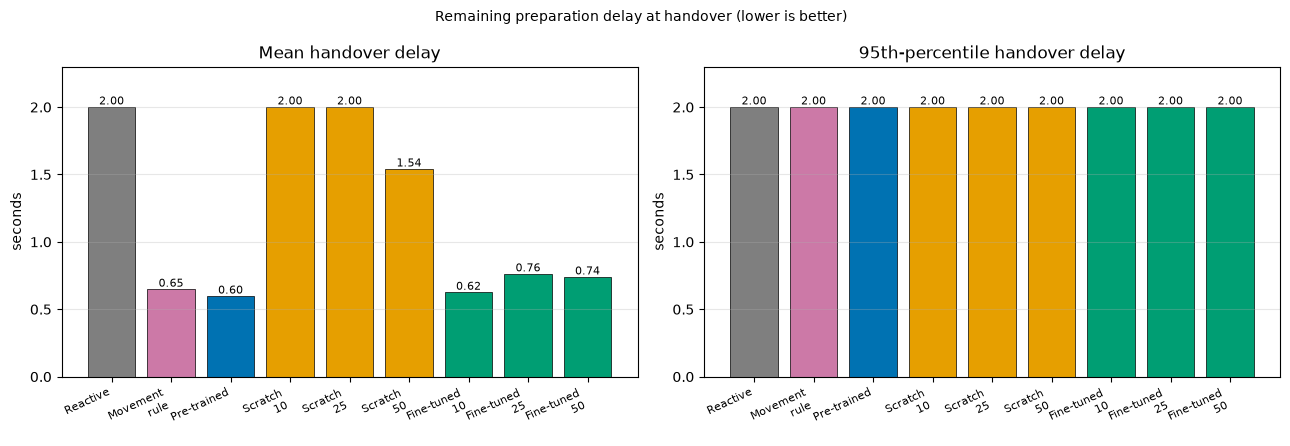

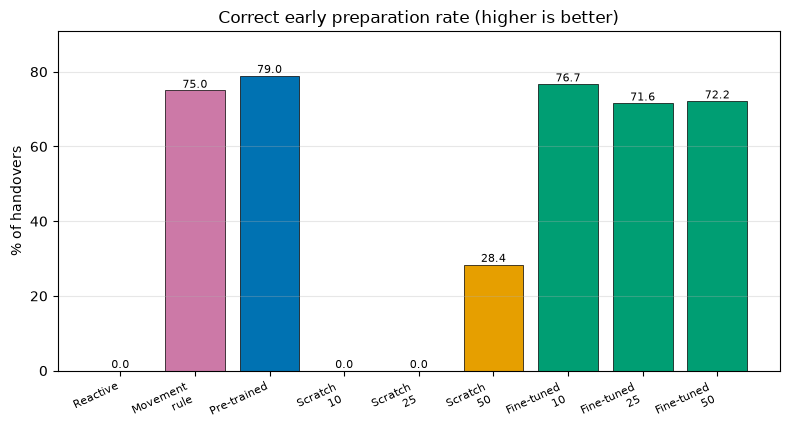

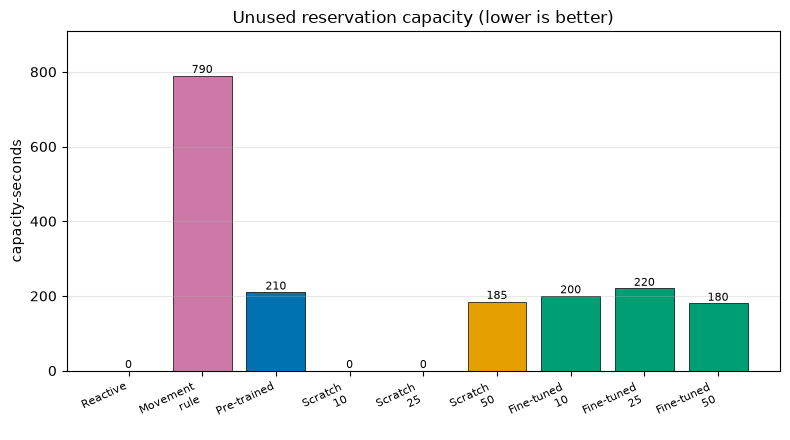

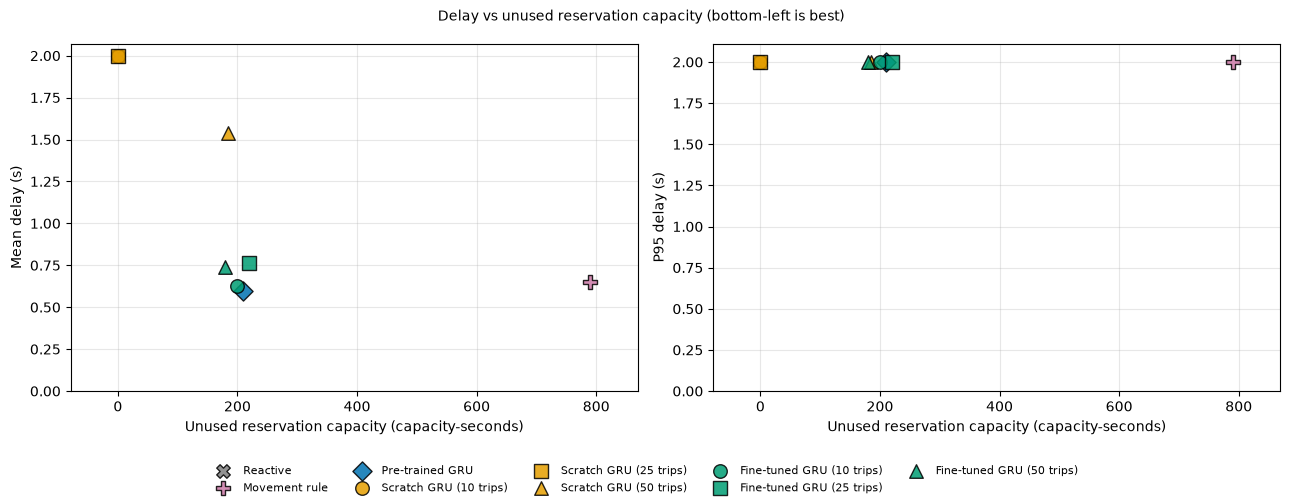

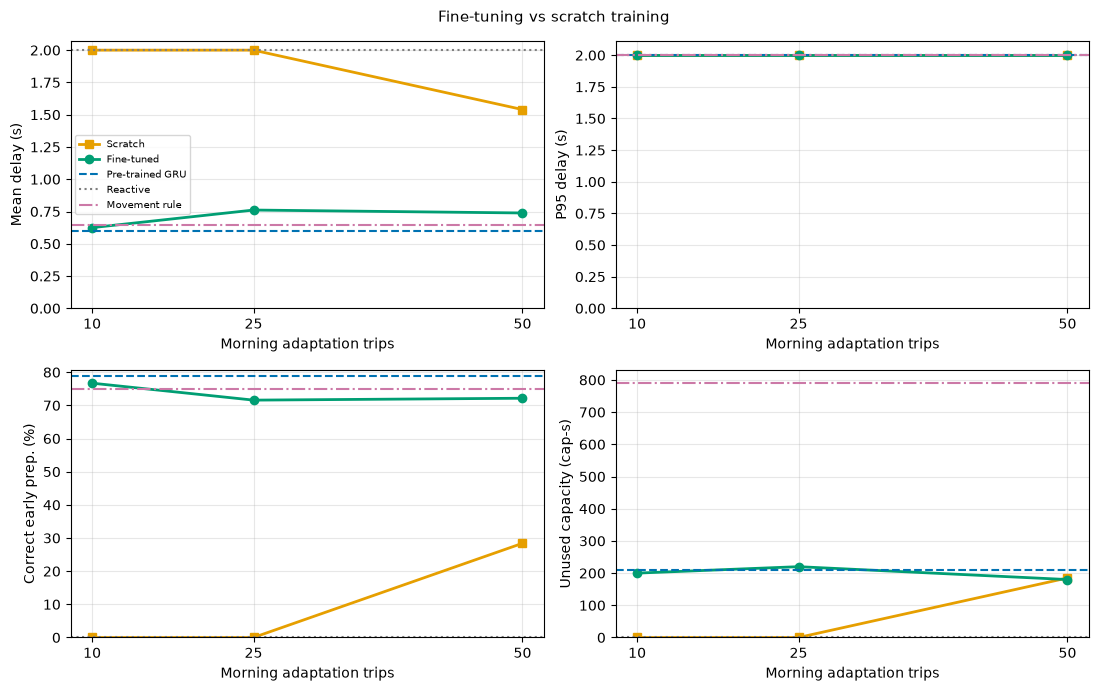

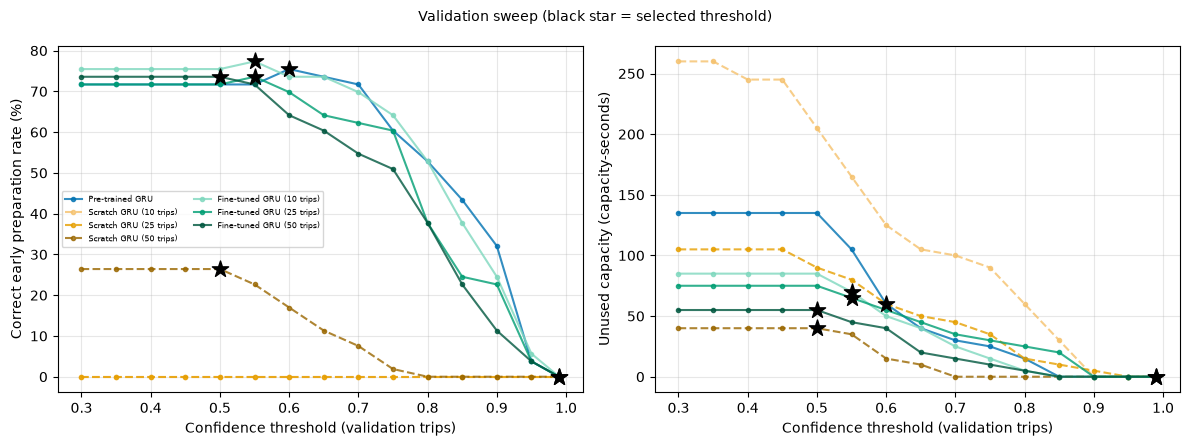

Charts saved: ['chart_correct_early_rate.png', 'chart_delay_vs_unused_tradeoff.png', 'chart_finetune_vs_scratch.png', 'chart_handover_delay.png', 'chart_unused_capacity.png', 'chart_validation_threshold_sweep.png']


In [11]:
T = test_table.set_index("approach")
EV = {k: T.loc[k, "status"] == "evaluated" for k in APPROACH_ORDER}
PENDING_NOTE = "" if all(EV.values()) else "“PENDING” = not evaluated (no values invented)"
SWEEP_COLORS = {"pretrained": "#0072B2", "scratch_10": "#F5C16C", "scratch_25": "#E69F00", "scratch_50": "#9A6700",
                "finetuned_10": "#7FD8BE", "finetuned_25": "#009E73", "finetuned_50": "#00573F"}


def save_fig(fig, name):
    fig.savefig(inside_out_dir(OUT_DIR / name), dpi=150, bbox_inches="tight")


def bar_panel(ax, col, title, ylabel, spec):
    for i, k in enumerate(APPROACH_ORDER):
        if not EV[k]:
            ax.bar(i, 0.0001, color="none")
            ax.text(i, 0, "PENDING", rotation=90, ha="center", va="bottom", color="gray", fontsize=8)
            continue
        value = T.loc[k, col]
        ax.bar(i, value, color=COLORS[k], edgecolor="black", linewidth=0.5)
        ax.text(i, value, format(value, spec), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(APPROACH_ORDER)))
    ax.set_xticklabels([SHORT[k] for k in APPROACH_ORDER], fontsize=8, rotation=25, ha="right")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.15)


# 1) delay: mean and P95
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bar_panel(axes[0], "mean_delay_s", "Mean handover delay", "seconds", ".2f")
bar_panel(axes[1], "p95_delay_s", "95th-percentile handover delay", "seconds", ".2f")
fig.suptitle("Remaining preparation delay at handover (lower is better)  " + PENDING_NOTE, fontsize=10)
fig.tight_layout()
save_fig(fig, "chart_handover_delay.png")
plt.show()

# 2) correct early preparation rate
fig, ax = plt.subplots(figsize=(8, 4.5))
bar_panel(ax, "correct_early_rate_pct", "Correct early preparation rate (higher is better)", "% of handovers", ".1f")
fig.tight_layout()
save_fig(fig, "chart_correct_early_rate.png")
plt.show()

# 3) unused reservation capacity
fig, ax = plt.subplots(figsize=(8, 4.5))
bar_panel(ax, "unused_capacity_s", "Unused reservation capacity (lower is better)", "capacity-seconds", ".0f")
fig.tight_layout()
save_fig(fig, "chart_unused_capacity.png")
plt.show()

# 4) trade-off: delay vs unused capacity (colour = family, marker shape = adaptation budget)
MARKERS = {"reactive": "X", "movement_rule": "P", "pretrained": "D", "scratch_10": "o", "scratch_25": "s", "scratch_50": "^",
           "finetuned_10": "o", "finetuned_25": "s", "finetuned_50": "^"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, label in ((axes[0], "mean_delay_s", "Mean delay (s)"), (axes[1], "p95_delay_s", "P95 delay (s)")):
    for k in APPROACH_ORDER:
        if EV[k]:
            ax.scatter(T.loc[k, "unused_capacity_s"], T.loc[k, col], s=95, marker=MARKERS[k], color=COLORS[k],
                       edgecolor="black", alpha=0.85, zorder=3, label=DISPLAY[k])
    ax.set_xlabel("Unused reservation capacity (capacity-seconds)")
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.margins(x=0.1, y=0.2)
    ax.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.suptitle("Delay vs unused reservation capacity (bottom-left is best)  " + PENDING_NOTE, fontsize=10)
fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, "chart_delay_vs_unused_tradeoff.png")
plt.show()

# 5) fine-tuned vs scratch at 10 / 25 / 50 trips
budgets = [10, 25, 50]
panels = [("mean_delay_s", "Mean delay (s)"), ("p95_delay_s", "P95 delay (s)"),
          ("correct_early_rate_pct", "Correct early prep. (%)"), ("unused_capacity_s", "Unused capacity (cap-s)")]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
any_pair = False
for ax, (col, label) in zip(axes.ravel(), panels):
    for fam, marker in (("scratch", "s"), ("finetuned", "o")):
        xs = [n for n in budgets if EV[f"{fam}_{n}"]]
        if xs:
            any_pair = True
            ax.plot(xs, [T.loc[f"{fam}_{n}", col] for n in xs], marker=marker, color=COLORS[f"{fam}_10"],
                    label="Fine-tuned" if fam == "finetuned" else "Scratch", linewidth=2)
    for k, style in (("pretrained", "--"), ("reactive", ":"), ("movement_rule", "-.")):
        if EV[k]:
            ax.axhline(T.loc[k, col], color=COLORS[k], linestyle=style, label=DISPLAY[k])
    ax.set_xticks(budgets)
    ax.set_xlabel("Morning adaptation trips")
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
if not any_pair:
    fig.text(0.5, 0.5, "GRU results PENDING\n(no checkpoint could be evaluated in this run)", ha="center", va="center",
             fontsize=16, color="gray")
fig.suptitle("Fine-tuning vs scratch training", fontsize=11)
fig.tight_layout()
save_fig(fig, "chart_finetune_vs_scratch.png")
plt.show()

# 6) validation threshold sweeps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
swept = val_table[(val_table.status == "evaluated")]
for name in GRU_MODELS:
    g = swept[swept.approach == name]
    for ax, col in zip(axes, ("correct_early_rate_pct", "unused_capacity_s")):
        ax.plot(g.threshold, g[col], marker=".", color=SWEEP_COLORS[name],
                linestyle={"pretrained": "-", "scratch": "--", "finetuned": "-"}[FAMILY[name]], alpha=0.8, label=DISPLAY[name])
        sel = g[g.selected]
        ax.scatter(sel.threshold, sel[col], marker="*", s=150, color="black", zorder=4)
axes[0].set_ylabel("Correct early preparation rate (%)")
axes[1].set_ylabel("Unused capacity (capacity-seconds)")
for ax in axes:
    ax.set_xlabel("Confidence threshold (validation trips)")
    ax.grid(alpha=0.3)
if len(swept):
    axes[0].legend(fontsize=6, ncol=2)
    fig.suptitle("Validation sweep (black star = selected threshold)", fontsize=10)
else:
    fig.text(0.5, 0.5, "PENDING — no validation predictions\n(checkpoints or PyTorch unavailable)", ha="center", va="center",
             fontsize=15, color="gray")
fig.tight_layout()
save_fig(fig, "chart_validation_threshold_sweep.png")
plt.show()
print("Charts saved:", sorted(p.name for p in OUT_DIR.glob("chart_*.png")))

## 11. Findings — generated from the numbers above
Every sentence below is produced by code from `test_comparison.csv`. If a model is PENDING, the corresponding comparison says so instead of
guessing. Nothing here is typed in advance.

In [12]:
def better(a, b, lower_is_better=True, tol=1e-9):
    if abs(a - b) <= tol:
        return "tied"
    return "better" if ((a < b) == lower_is_better) else "worse"


def build_findings(t):
    t = t.set_index("approach")
    ev = t[t.status == "evaluated"]
    out = []
    n_h = int(ev.handovers.iloc[0])
    out.append(f"**Scope.** {len(ev)} of 9 approaches evaluated on {int(ev.test_trips.iloc[0])} held-out trips with {n_h} handovers each "
               f"(all approaches see the same handovers).")
    pend = t[t.status != "evaluated"]
    if len(pend):
        out.append("**Pending (not evaluated, no values invented):** " + ", ".join(DISPLAY[k] for k in pend.index) + ".")

    # baselines
    if {"reactive", "movement_rule"} <= set(ev.index):
        re, mv = ev.loc["reactive"], ev.loc["movement_rule"]
        out.append(f"**Baselines.** Reactive: mean delay {re.mean_delay_s:.3f} s, P95 {re.p95_delay_s:.2f} s, correct early rate {re.correct_early_rate_pct:.1f}%, "
                   f"unused capacity {re.unused_capacity_s:.0f}. Movement-rule: mean delay {mv.mean_delay_s:.3f} s, P95 {mv.p95_delay_s:.2f} s, "
                   f"correct early rate {mv.correct_early_rate_pct:.1f}%, unused capacity {mv.unused_capacity_s:.0f} capacity-seconds "
                   f"({int(mv.wrong_reservations)} wrong reservations).")

    # fine-tuned vs scratch
    out.append("**Fine-tuning vs scratch training.**")
    wins = {"mean_delay_s": 0, "p95_delay_s": 0, "correct_early_rate_pct": 0, "unused_capacity_s": 0}
    pairs = 0
    for n in (10, 25, 50):
        f_, s_ = f"finetuned_{n}", f"scratch_{n}"
        if f_ in ev.index and s_ in ev.index:
            pairs += 1
            f, s = ev.loc[f_], ev.loc[s_]
            verdicts = {"mean_delay_s": better(f.mean_delay_s, s.mean_delay_s), "p95_delay_s": better(f.p95_delay_s, s.p95_delay_s),
                        "correct_early_rate_pct": better(f.correct_early_rate_pct, s.correct_early_rate_pct, False),
                        "unused_capacity_s": better(f.unused_capacity_s, s.unused_capacity_s)}
            for k, v in verdicts.items():
                wins[k] += v == "better"
            out.append(f"- {n} trips: fine-tuned vs scratch — mean delay {f.mean_delay_s:.3f} vs {s.mean_delay_s:.3f} s ({verdicts['mean_delay_s']}), "
                       f"P95 {f.p95_delay_s:.2f} vs {s.p95_delay_s:.2f} s ({verdicts['p95_delay_s']}), "
                       f"correct early {f.correct_early_rate_pct:.1f} vs {s.correct_early_rate_pct:.1f}% ({verdicts['correct_early_rate_pct']}), "
                       f"unused capacity {f.unused_capacity_s:.0f} vs {s.unused_capacity_s:.0f} ({verdicts['unused_capacity_s']}); "
                       f"thresholds {f.confidence_threshold:.2f} vs {s.confidence_threshold:.2f}.")
        else:
            missing = [DISPLAY[k] for k in (f_, s_) if k not in ev.index]
            out.append(f"- {n} trips: PENDING ({', '.join(missing)} not evaluated), so no comparison can be made.")
    if pairs:
        out.append(f"  Across the {pairs} budget(s) compared, fine-tuned was better than scratch on mean delay in {wins['mean_delay_s']}, "
                   f"P95 delay in {wins['p95_delay_s']}, correct early rate in {wins['correct_early_rate_pct']} and unused capacity in {wins['unused_capacity_s']}.")
        if "pretrained" in ev.index:
            gain = [f"{n}: {ev.loc['pretrained'].mean_delay_s - ev.loc[f'finetuned_{n}'].mean_delay_s:+.3f} s"
                    for n in (10, 25, 50) if f"finetuned_{n}" in ev.index]
            out.append("  Mean-delay change from adapting the pre-trained model (pre-trained minus fine-tuned; positive = fine-tuning helped): " + "; ".join(gain) + ".")
    # trend with more data
    for fam in ("finetuned", "scratch"):
        seq = [(n, ev.loc[f"{fam}_{n}"].mean_delay_s) for n in (10, 25, 50) if f"{fam}_{n}" in ev.index]
        if len(seq) >= 2:
            out.append(f"  {fam.replace('finetuned', 'Fine-tuned').replace('scratch', 'Scratch')} mean delay by adaptation trips: "
                       + ", ".join(f"{n}→{v:.3f} s" for n, v in seq) + ".")

    # trade-off
    out.append("**Delay vs unused capacity.**")
    if "reactive" in ev.index and len(ev) > 1:
        re = ev.loc["reactive"]
        rows = []
        for k in ev.index:
            if k == "reactive":
                continue
            saved = (re.mean_delay_s - ev.loc[k].mean_delay_s) * n_h
            rows.append(f"- {DISPLAY[k]}: mean delay {ev.loc[k].mean_delay_s - re.mean_delay_s:+.3f} s vs reactive, "
                        f"unused capacity {ev.loc[k].unused_capacity_s:.0f} capacity-s"
                        + (f", i.e. {ev.loc[k].unused_capacity_s / saved:.2f} capacity-s per second of total delay saved." if saved > 0 else
                           ", no delay saved relative to reactive."))
        out += rows
    pts = ev[["mean_delay_s", "unused_capacity_s"]]
    dominated = {a for a in pts.index for b in pts.index if a != b
                 and pts.loc[b].mean_delay_s <= pts.loc[a].mean_delay_s and pts.loc[b].unused_capacity_s <= pts.loc[a].unused_capacity_s
                 and (pts.loc[b] < pts.loc[a]).any()}
    out.append("  Not dominated on (mean delay, unused capacity) — i.e. on the efficient frontier: "
               + ", ".join(DISPLAY[k] for k in pts.index if k not in dominated) + ".")
    if len(ev) >= 4:
        rho = pts.mean_delay_s.corr(pts.unused_capacity_s, method="spearman")
        if pd.notna(rho):
            out.append(f"  Spearman rank correlation between mean delay and unused capacity across the {len(ev)} evaluated approaches: {rho:+.2f} "
                       "(negative: higher unused capacity goes with lower delay; positive: the opposite; descriptive only, not causal).")
    out.append("**Caveats.** One simulated scenario, one trained model per configuration (training seed fixed by Person 1), and "
               f"{int(ev.test_trips.iloc[0])} test trips on a shared clock with capacity {P3_CONSTANTS['CAPACITY']} per cell; no confidence intervals were computed, "
               "so small differences should not be over-interpreted. Results describe this simulation and its assumptions only.")
    return out


FINDINGS = build_findings(test_table)
display(Markdown("\n\n".join(FINDINGS)))

**Scope.** 9 of 9 approaches evaluated on 100 held-out trips with 176 handovers each (all approaches see the same handovers).

**Baselines.** Reactive: mean delay 2.000 s, P95 2.00 s, correct early rate 0.0%, unused capacity 0. Movement-rule: mean delay 0.648 s, P95 2.00 s, correct early rate 75.0%, unused capacity 790 capacity-seconds (2 wrong reservations).

**Fine-tuning vs scratch training.**

- 10 trips: fine-tuned vs scratch — mean delay 0.625 vs 2.000 s (better), P95 2.00 vs 2.00 s (tied), correct early 76.7 vs 0.0% (better), unused capacity 200 vs 0 (worse); thresholds 0.55 vs 0.99.

- 25 trips: fine-tuned vs scratch — mean delay 0.761 vs 2.000 s (better), P95 2.00 vs 2.00 s (tied), correct early 71.6 vs 0.0% (better), unused capacity 220 vs 0 (worse); thresholds 0.55 vs 0.99.

- 50 trips: fine-tuned vs scratch — mean delay 0.739 vs 1.540 s (better), P95 2.00 vs 2.00 s (tied), correct early 72.2 vs 28.4% (better), unused capacity 180 vs 185 (better); thresholds 0.50 vs 0.50.

  Across the 3 budget(s) compared, fine-tuned was better than scratch on mean delay in 3, P95 delay in 0, correct early rate in 3 and unused capacity in 1.

  Mean-delay change from adapting the pre-trained model (pre-trained minus fine-tuned; positive = fine-tuning helped): 10: -0.028 s; 25: -0.165 s; 50: -0.142 s.

  Fine-tuned mean delay by adaptation trips: 10→0.625 s, 25→0.761 s, 50→0.739 s.

  Scratch mean delay by adaptation trips: 10→2.000 s, 25→2.000 s, 50→1.540 s.

**Delay vs unused capacity.**

- Movement rule: mean delay -1.352 s vs reactive, unused capacity 790 capacity-s, i.e. 3.32 capacity-s per second of total delay saved.

- Pre-trained GRU: mean delay -1.403 s vs reactive, unused capacity 210 capacity-s, i.e. 0.85 capacity-s per second of total delay saved.

- Scratch GRU (10 trips): mean delay +0.000 s vs reactive, unused capacity 0 capacity-s, no delay saved relative to reactive.

- Scratch GRU (25 trips): mean delay +0.000 s vs reactive, unused capacity 0 capacity-s, no delay saved relative to reactive.

- Scratch GRU (50 trips): mean delay -0.460 s vs reactive, unused capacity 185 capacity-s, i.e. 2.28 capacity-s per second of total delay saved.

- Fine-tuned GRU (10 trips): mean delay -1.375 s vs reactive, unused capacity 200 capacity-s, i.e. 0.83 capacity-s per second of total delay saved.

- Fine-tuned GRU (25 trips): mean delay -1.239 s vs reactive, unused capacity 220 capacity-s, i.e. 1.01 capacity-s per second of total delay saved.

- Fine-tuned GRU (50 trips): mean delay -1.261 s vs reactive, unused capacity 180 capacity-s, i.e. 0.81 capacity-s per second of total delay saved.

  Not dominated on (mean delay, unused capacity) — i.e. on the efficient frontier: Reactive, Pre-trained GRU, Scratch GRU (10 trips), Scratch GRU (25 trips), Fine-tuned GRU (10 trips), Fine-tuned GRU (50 trips).

  Spearman rank correlation between mean delay and unused capacity across the 9 evaluated approaches: -0.78 (negative: higher unused capacity goes with lower delay; positive: the opposite; descriptive only, not causal).

**Caveats.** One simulated scenario, one trained model per configuration (training seed fixed by Person 1), and 100 test trips on a shared clock with capacity 10 per cell; no confidence intervals were computed, so small differences should not be over-interpreted. Results describe this simulation and its assumptions only.

## 12. Final integrity checks and completion report

In [13]:
# ---- previous work untouched? ----
FILES_AFTER = snapshot_existing_files()
changed = [f for f in FILES_BEFORE if FILES_BEFORE[f] != FILES_AFTER.get(f)]
added = [f for f in FILES_AFTER if f not in FILES_BEFORE]
assert not changed and not added, f"Existing files changed/added: {changed} {added}"
print(f"Existing files unchanged: {len(FILES_BEFORE)} checked, 0 modified, 0 added or removed.")
try:
    git = subprocess.run(["git", "status", "--porcelain"], cwd=PROJECT_DIR, capture_output=True, text=True, timeout=20)
    if git.returncode == 0:
        print("git status --porcelain (only new Person 4 files should be listed):")
        print(git.stdout or "  (clean)")
except Exception as exc:
    print("git status unavailable:", exc)

# ---- write a Markdown summary of tables + findings ----
def md_table(df):
    head = "| " + " | ".join(df.columns) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join("| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False))


summary = ["# Person 4 — integration summary", "",
           f"Data sources — validation: {info['validation_data']['source']}; test: {info['test_data']['source']}", "",
           md_table(PRESENT), "", "## Findings", ""] + FINDINGS
inside_out_dir(OUT_DIR / "integration_summary.md").write_text("\n".join(summary), encoding="utf-8")

# ---- report ----
evaluated = [k for k in APPROACH_ORDER if EV[k]]
pending_keys = [k for k in APPROACH_ORDER if not EV[k]]
print("\nOutputs in integration_results/:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT_DIR), f"({p.stat().st_size:,} bytes)")
print("\nEvaluated :", ", ".join(evaluated) or "none")
print("PENDING   :", ", ".join(pending_keys) or "none")
for k in pending_keys:
    print(f"   - {k}: {T.loc[k, 'status_detail']}")
print("Reproducibility (two full runs identical):", repro["all_match"])

Existing files unchanged: 26 checked, 0 modified, 0 added or removed.
git status --porcelain (only new Person 4 files should be listed):
 M README.md
 M handover_simulator.ipynb
 M integration_results/chart_correct_early_rate.png
 M integration_results/chart_delay_vs_unused_tradeoff.png
 M integration_results/chart_finetune_vs_scratch.png
 M integration_results/chart_handover_delay.png
 M integration_results/chart_unused_capacity.png
 M integration_results/chart_validation_threshold_sweep.png
 M integration_results/integration_summary.md
 M integration_results/reproducibility.json
 M integration_results/settings.json
 M integration_results/test_comparison.csv
 M integration_results/validation_thresholds.csv
 M main.ipynb
 M requirements.txt
 M train_model.ipynb
?? .verify_branch.py
?? .verify_finish.py
?? .verify_stale.py
?? integration_results/validation_predictions/


Outputs in integration_results/:
   .DS_Store (6,148 bytes)
   chart_correct_early_rate.png (42,110 bytes)
   chart_d